In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader
from torchvision.utils import make_grid
from pytorch_fid import fid_score  # For FID evaluation

# Define VAE Architecture
class VAE(nn.Module):
    def __init__(self, latent_dim=20):
        super(VAE, self).__init__()
        self.latent_dim = latent_dim
        
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(784, 400),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(400, latent_dim)
        self.fc_logvar = nn.Linear(400, latent_dim)
        
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 400),
            nn.ReLU(),
            nn.Linear(400, 784),
            nn.Sigmoid()
        )
    
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    
    def forward(self, x):
        x = x.view(-1, 784)  # Flatten the image
        h = self.encoder(x)
        mu, logvar = self.fc_mu(h), self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        x_recon = self.decoder(z)
        return x_recon, mu, logvar

# Loss Function: ELBO (Reconstruction Loss + KL Divergence)
def loss_function(recon_x, x, mu, logvar):
    recon_loss = nn.BCELoss(reduction='sum')(recon_x, x.view(-1, 784))
    kl_div = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + kl_div

# Load MNIST Dataset
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vae = VAE().to(device)
optimizer = optim.Adam(vae.parameters(), lr=1e-3)

# Train VAE
epochs = 25
vae.train()
for epoch in range(epochs):
    train_loss = 0
    for batch, (data, _) in enumerate(train_loader):
        data = data.to(device)
        optimizer.zero_grad()
        recon_batch, mu, logvar = vae(data)
        loss = loss_function(recon_batch, data, mu, logvar)
        loss.backward()
        train_loss += loss.item()
        optimizer.step()
    print(f"Epoch {epoch+1}, Loss: {train_loss/len(train_loader.dataset):.4f}")


/home/samyukta/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Epoch 1, Loss: 164.7415
Epoch 2, Loss: 121.8861
Epoch 3, Loss: 114.8396
Epoch 4, Loss: 111.7131
Epoch 5, Loss: 109.9610
Epoch 6, Loss: 108.7436
Epoch 7, Loss: 107.8987
Epoch 8, Loss: 107.2135
Epoch 9, Loss: 106.7192
Epoch 10, Loss: 106.2550
Epoch 11, Loss: 105.9201
Epoch 12, Loss: 105.5939
Epoch 13, Loss: 105.3431
Epoch 14, Loss: 105.1094
Epoch 15, Loss: 104.8246
Epoch 16, Loss: 104.6774
Epoch 17, Loss: 104.4600
Epoch 18, Loss: 104.3742
Epoch 19, Loss: 104.1383
Epoch 20, Loss: 103.9851
Epoch 21, Loss: 103.8748
Epoch 22, Loss: 103.7263
Epoch 23, Loss: 103.6044
Epoch 24, Loss: 103.4697
Epoch 25, Loss: 103.3854


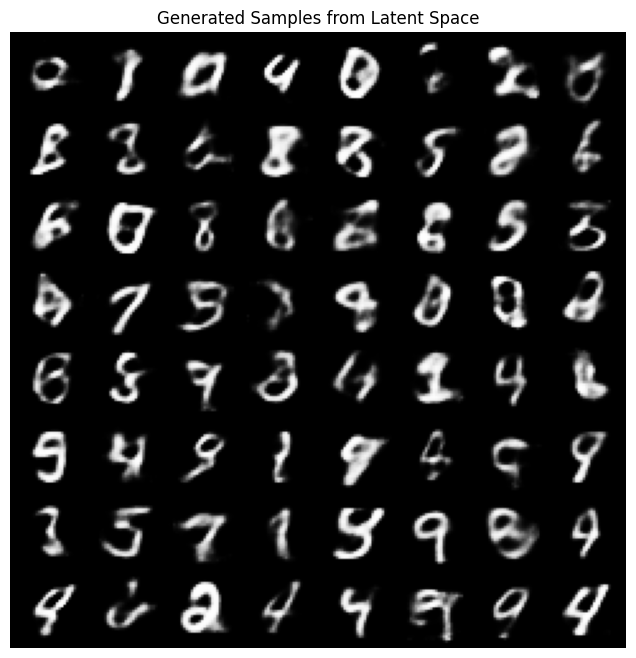

In [2]:
# Visualize the generative process by sampling from latent space
vae.eval()
z_samples = torch.randn(64, 20).to(device)
generated_images = vae.decoder(z_samples).detach().cpu()

def show_images(images, title):
    images = images.view(-1, 1, 28, 28)
    grid = make_grid(images, nrow=8, normalize=True)
    plt.figure(figsize=(8, 8))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(title)
    plt.axis("off")
    plt.show()

# Show generated images
show_images(generated_images, "Generated Samples from Latent Space")

In [11]:
import os
from torchvision import transforms

# Define image directories
real_images_path = "./real_images"
fake_images_path = "./fake_images"

# Ensure directories exist
os.makedirs(real_images_path, exist_ok=True)
os.makedirs(fake_images_path, exist_ok=True)

# Convert tensor to PIL before saving
to_pil = transforms.ToPILImage()

# Save real images
for i in range(64):
    image_path = os.path.join(real_images_path, f"real_{i}.png")
    pil_image = to_pil(train_dataset[i][0])  # Convert tensor to PIL image
    pil_image.save(image_path)

# Save generated images
for i in range(64):
    image_path = os.path.join(fake_images_path, f"fake_{i}.png")
    pil_image = to_pil(generated_images[i].view(1, 28, 28))  # Convert tensor to PIL
    pil_image.save(image_path)

# Compute FID
compute_fid(os.path.abspath(real_images_path), os.path.abspath(fake_images_path))


RuntimeError: Invalid path: h